## Part 1 — Exploratory Data Analysis

### Dataset Description

The E-Commerce Shipping dataset contains 10,999 records and 12 columns, including shipment, product, and customer-related information.

**Source:** [E-Commerce Shipping Data – Kaggle](https://www.kaggle.com/datasets/prachi13/customer-analytics)

| Feature | Description |
|---|---|
| `ID` | A unique identifier assigned to each record. |
| `Warehouse_block` | The warehouse section responsible for handling the shipment. |
| `Mode_of_Shipment` | The transportation method used to deliver the product, such as Ship, Flight, or Road. |
| `Customer_care_calls` | The number of customer service calls related to the shipment. |
| `Customer_rating` | The customer's rating on a scale from 1 (worst) to 5 (best). |
| `Cost_of_the_Product` | The cost of the product in US dollars. |
| `Prior_purchases` | The number of previous purchases made by the customer. |
| `Product_importance` | The product's importance level, categorized as low, medium, or high. |
| `Gender` | The recorded gender of the customer. |
| `Discount_offered` | The discount value offered for the product. |
| `Weight_in_gms` | The weight of the product in grams. |
| `Reached.on.Time_Y.N` | The target variable indicating whether the shipment was delayed (1) or delivered on time (0). |

### Project Objective

The objective of this project is to investigate the dataset and prepare it for a binary classification task that predicts whether an e-commerce shipment will be delayed.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
df = pd.read_csv("Train.csv")

# Display first five rows
print("First 5 rows:")
print(df.head())

First 5 rows:
   ID Warehouse_block Mode_of_Shipment  Customer_care_calls  Customer_rating  \
0   1               D           Flight                    4                2   
1   2               F           Flight                    4                5   
2   3               A           Flight                    2                2   
3   4               B           Flight                    3                3   
4   5               C           Flight                    2                2   

   Cost_of_the_Product  Prior_purchases Product_importance Gender  \
0                  177                3                low      F   
1                  216                2                low      M   
2                  183                4                low      M   
3                  176                4             medium      M   
4                  184                3             medium      F   

   Discount_offered  Weight_in_gms  Reached.on.Time_Y.N  
0                44           12

In [3]:
# Dataset dimensions
print("\nDataset shape:")
print(df.shape)


Dataset shape:
(10999, 12)


In [4]:
# Column names and data types
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   10999 non-null  int64
 1   Warehouse_block      10999 non-null  str  
 2   Mode_of_Shipment     10999 non-null  str  
 3   Customer_care_calls  10999 non-null  int64
 4   Customer_rating      10999 non-null  int64
 5   Cost_of_the_Product  10999 non-null  int64
 6   Prior_purchases      10999 non-null  int64
 7   Product_importance   10999 non-null  str  
 8   Gender               10999 non-null  str  
 9   Discount_offered     10999 non-null  int64
 10  Weight_in_gms        10999 non-null  int64
 11  Reached.on.Time_Y.N  10999 non-null  int64
dtypes: int64(8), str(4)
memory usage: 1.0 MB


In [5]:
# Missing values
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64


In [6]:
# Target class distribution
print("\nTarget distribution:")
print(df["Reached.on.Time_Y.N"].value_counts())


Target distribution:
Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64


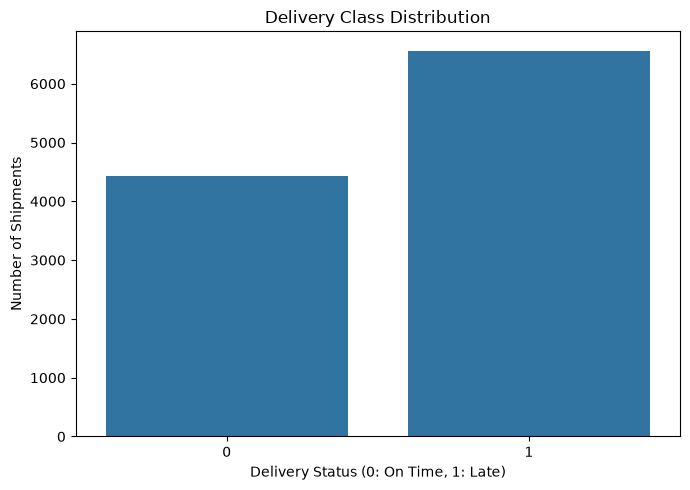

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Reached.on.Time_Y.N"
)

plt.title("Delivery Class Distribution")
plt.xlabel("Delivery Status (0: On Time, 1: Late)")
plt.ylabel("Number of Shipments")

plt.tight_layout()
plt.show()

In [9]:
# Descriptive statistics for numerical features
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,10999.0,5500.000000,3175.282140,1.0,2750.5,5500.0,8249.5,10999.0
Customer_care_calls,10999.0,4.054459,1.141490,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,3.567597,1.522860,2.0,3.0,3.0,4.0,10.0
Discount_offered,10999.0,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0
Reached.on.Time_Y.N,10999.0,0.596691,0.490584,0.0,0.0,1.0,1.0,1.0


In [10]:
# Descriptive statistics for categorical features
display(df.describe(include=["object", "category"]).T)

C:\Users\ghost\AppData\Local\Temp\ipykernel_6060\3604930255.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=["object", "category"]).T)


,count,unique,top,freq
Warehouse_block,10999,5,F,3666
Mode_of_Shipment,10999,3,Ship,7462
Product_importance,10999,3,low,5297
Gender,10999,2,F,5545


In [25]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Check duplicates excluding the ID column
print(
    "Duplicates excluding ID:",
    df.drop(columns=["ID"]).duplicated().sum()
)

# Number of unique values in each column
print("\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

Duplicate rows: 0
Duplicates excluding ID: 0

Unique values per column:


,Unique Values
ID,10999
Warehouse_block,5
Mode_of_Shipment,3
Customer_care_calls,6
Customer_rating,5
Cost_of_the_Product,215
Prior_purchases,8
Product_importance,3
Gender,2
Discount_offered,65


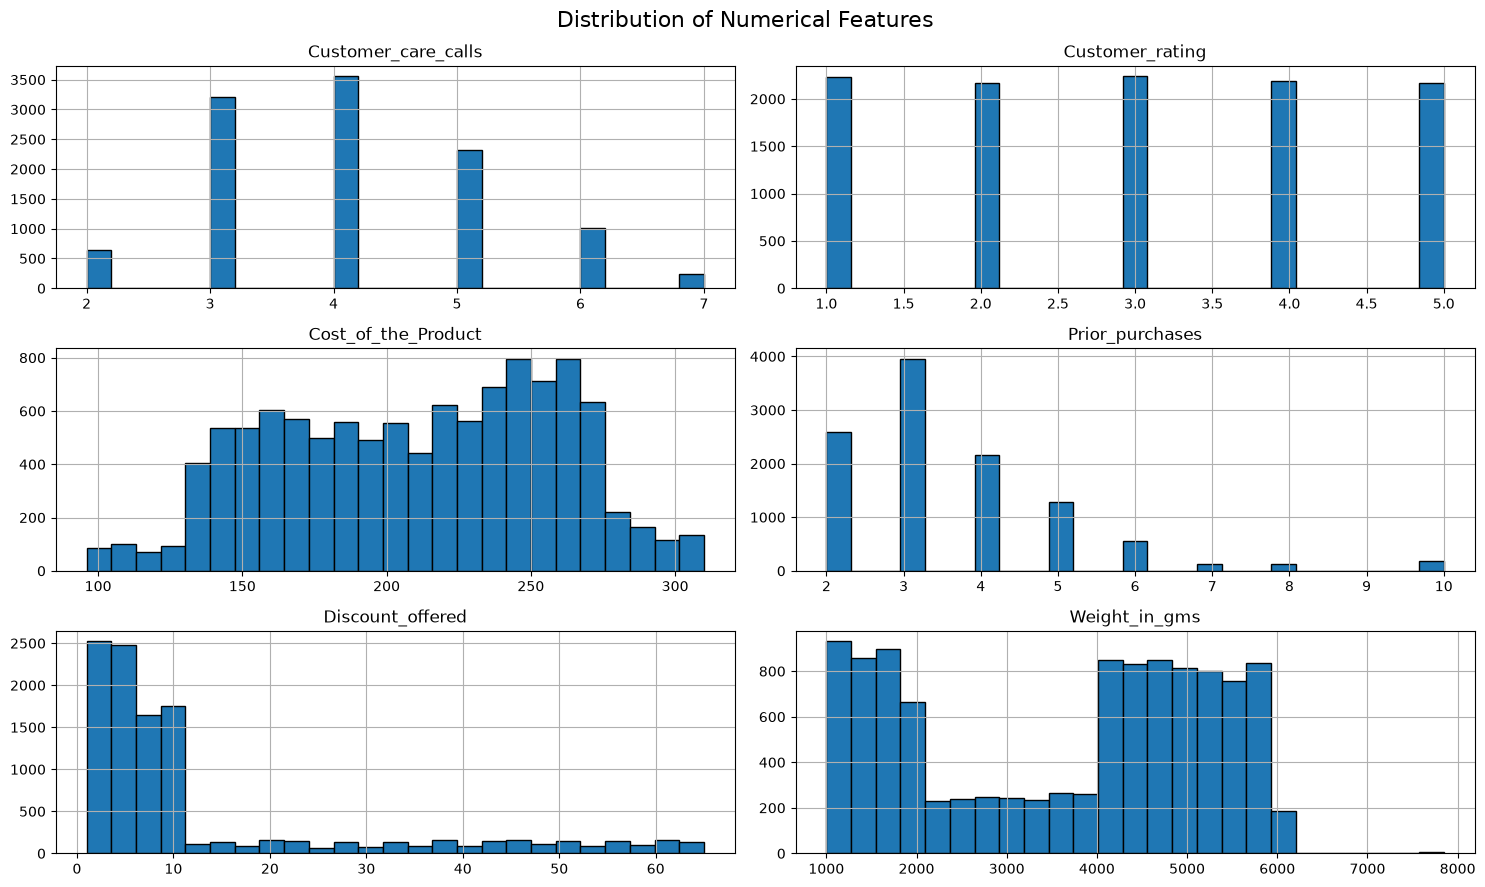

In [ ]:
#Distributions of numerical features
numerical_cols = [
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms"
]

df[numerical_cols].hist(
    bins=25,
    figsize=(15, 9),
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
#Categorical Feature Distributions
categorical_cols = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender"
]

for col in categorical_cols:
    print(f"\n{col}")
    display(df[col].value_counts())


Warehouse_block


Warehouse_block
F    3666
D    1834
A    1833
B    1833
C    1833
Name: count, dtype: int64


Mode_of_Shipment


Mode_of_Shipment
Ship      7462
Flight    1777
Road      1760
Name: count, dtype: int64


Product_importance


Product_importance
low       5297
medium    4754
high       948
Name: count, dtype: int64


Gender


Gender
F    5545
M    5454
Name: count, dtype: int64

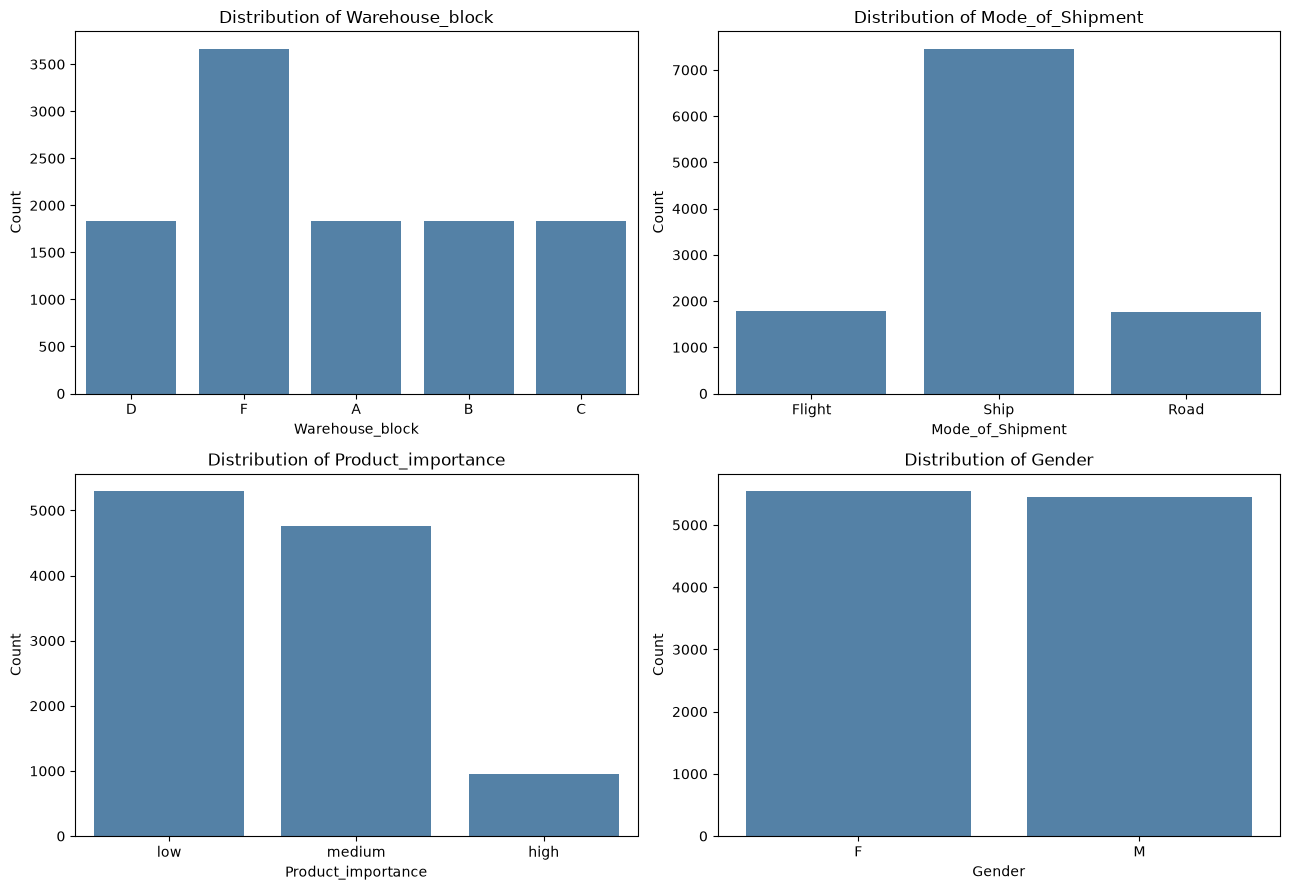

In [ ]:
#Categorical Feature Distributions' Graphics
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flat, categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        ax=ax,
        color="steelblue"
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

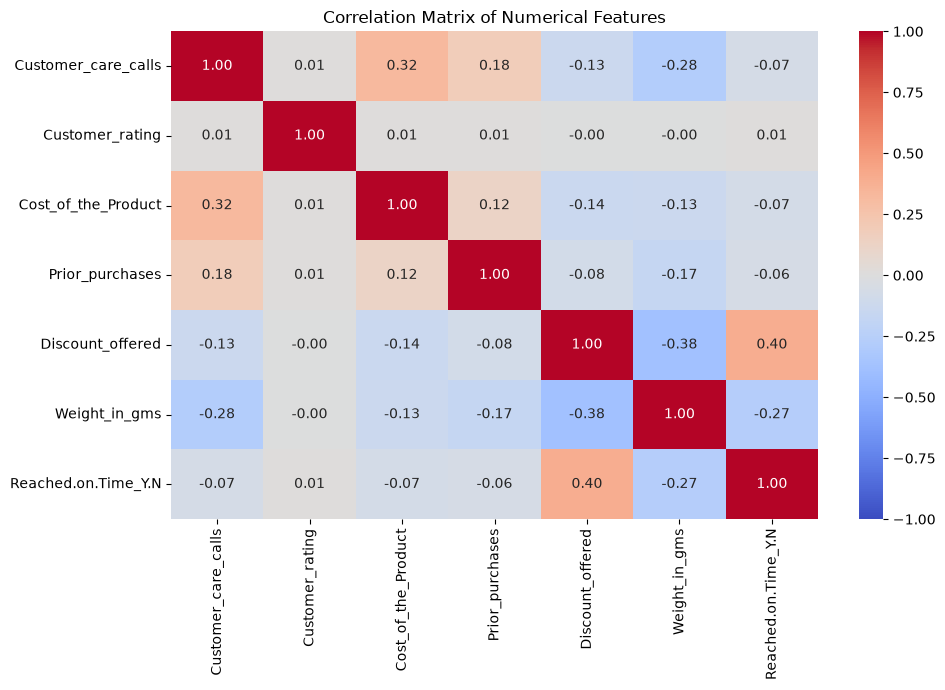

In [29]:
# Select numerical features and target
corr_cols = numerical_cols + ["Reached.on.Time_Y.N"]

correlation_matrix = df[corr_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [35]:
# Examine delivery status for different discount ranges
df["Discount_Group"] = pd.cut(
    df["Discount_offered"],
    bins=[0, 10, 20, 30, 40, 50, 70],
    include_lowest=True
)

discount_summary = pd.crosstab(
    df["Discount_Group"],
    df["Reached.on.Time_Y.N"]
)

discount_summary["Total"] = discount_summary.sum(axis=1)

discount_summary["Delay_Rate_%"] = (
    discount_summary[1] / discount_summary["Total"] * 100
).round(2)

display(discount_summary)

Reached.on.Time_Y.N,0,1,Total,Delay_Rate_%
Discount_Group,,,,
"(-0.001, 10.0]",4436,3916,8352,46.89
"(10.0, 20.0]",0,496,496,100.00
"(20.0, 30.0]",0,441,441,100.00
"(30.0, 40.0]",0,470,470,100.00
"(40.0, 50.0]",0,507,507,100.00
"(50.0, 70.0]",0,733,733,100.00


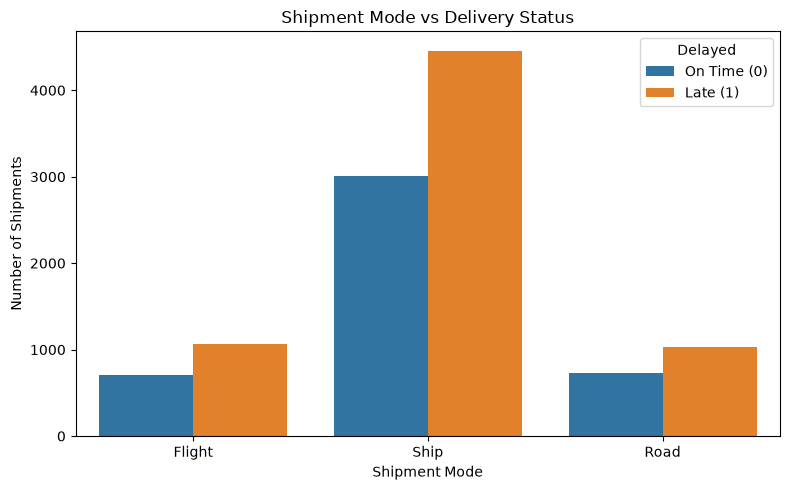

In [ ]:
#Feature vs Target Analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Mode_of_Shipment",
    hue="Reached.on.Time_Y.N"
)

plt.title("Shipment Mode vs Delivery Status")
plt.xlabel("Shipment Mode")
plt.ylabel("Number of Shipments")
plt.legend(title="Delayed", labels=["On Time (0)", "Late (1)"])

plt.tight_layout()
plt.show()

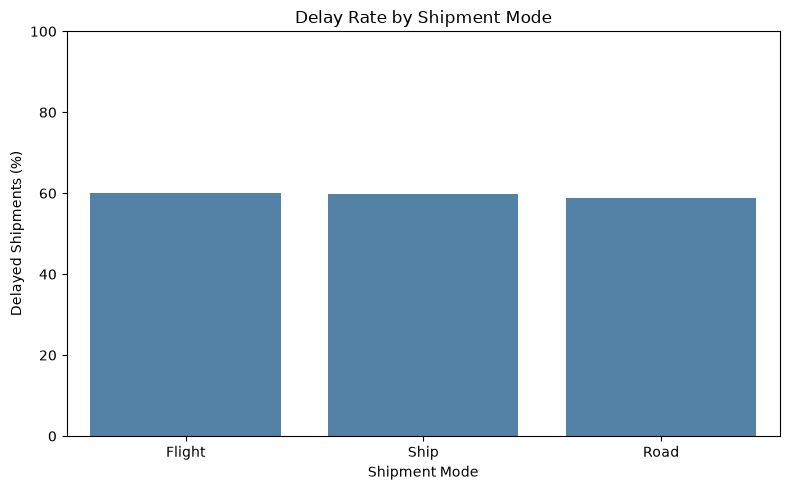

In [33]:
delay_rate = (
    df.groupby("Mode_of_Shipment")["Reached.on.Time_Y.N"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=delay_rate.index,
    y=delay_rate.values,
    color="steelblue"
)

plt.title("Delay Rate by Shipment Mode")
plt.xlabel("Shipment Mode")
plt.ylabel("Delayed Shipments (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

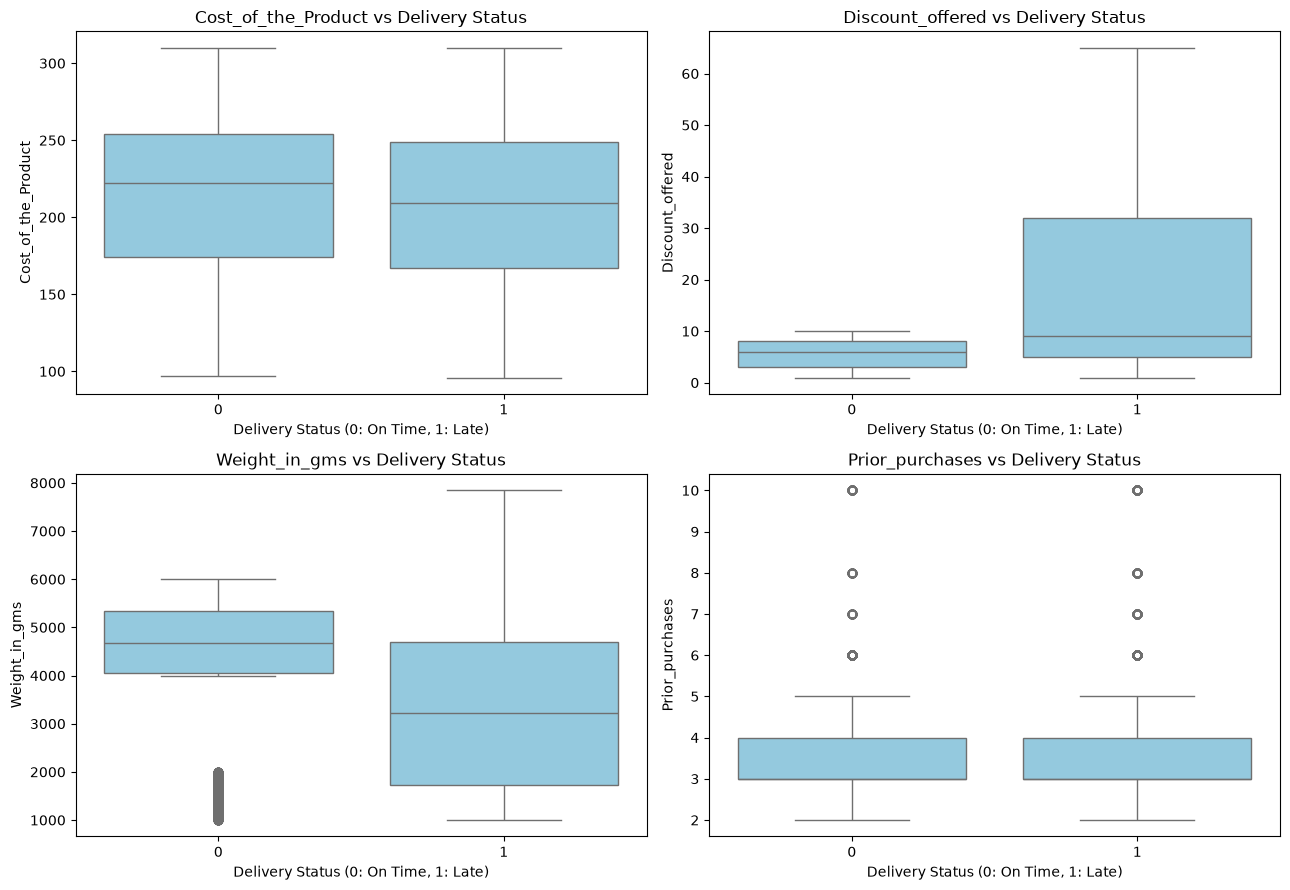

In [18]:
features_to_compare = [
    "Cost_of_the_Product",
    "Discount_offered",
    "Weight_in_gms",
    "Prior_purchases"
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(axes.flat, features_to_compare):
    sns.boxplot(
        data=df,
        x="Reached.on.Time_Y.N",
        y=col,
        ax=ax,
        color="skyblue"
    )
    ax.set_title(f"{col} vs Delivery Status")
    ax.set_xlabel("Delivery Status (0: On Time, 1: Late)")

plt.tight_layout()
plt.show()

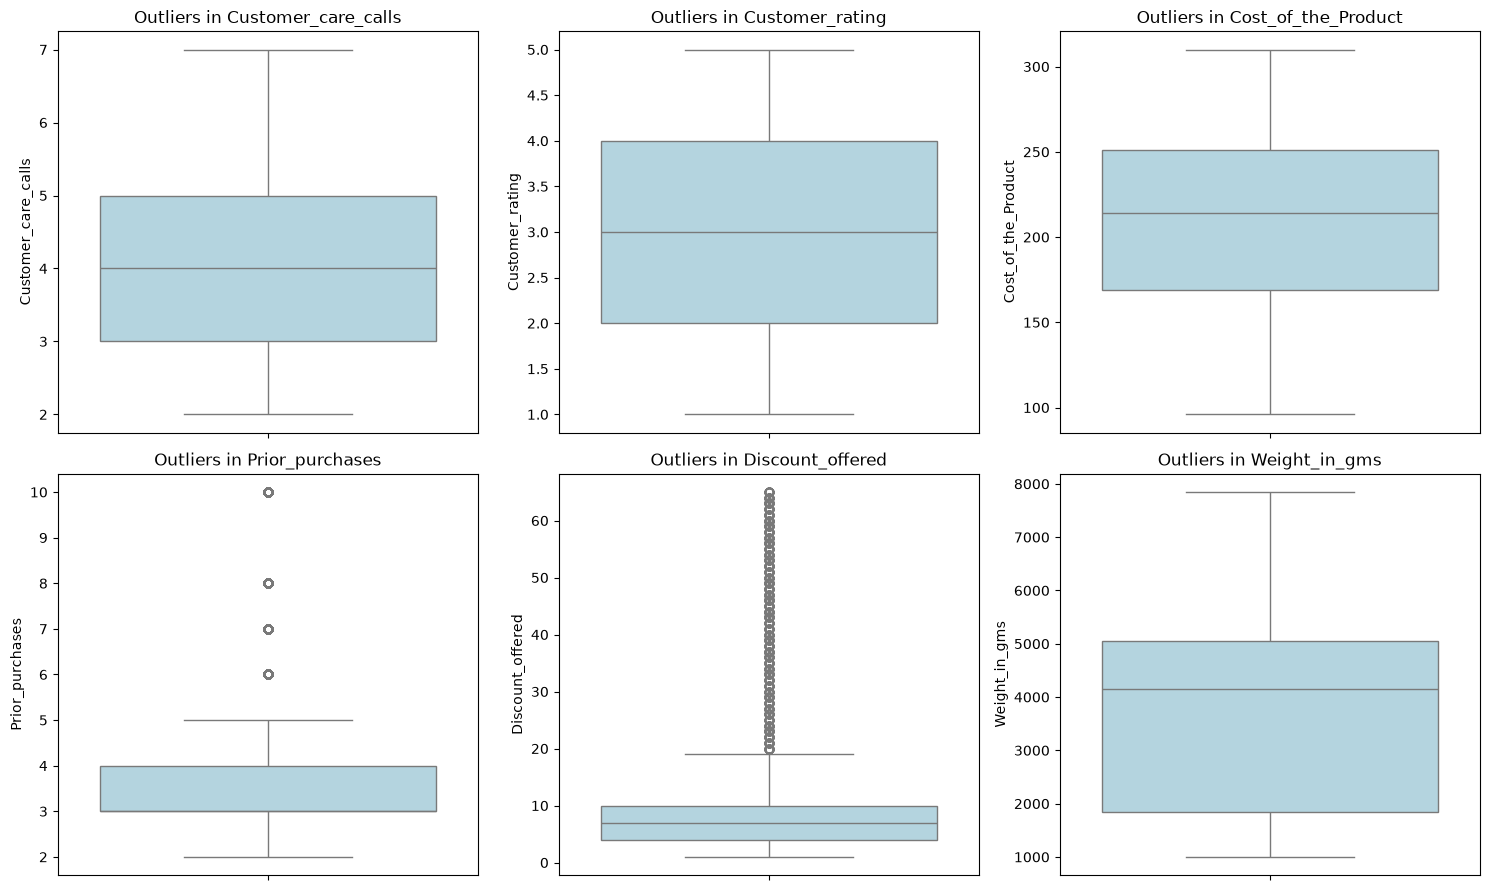

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, col in zip(axes.flat, numerical_cols):
    sns.boxplot(
        y=df[col],
        ax=ax,
        color="lightblue"
    )
    ax.set_title(f"Outliers in {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [32]:
numerical_cols = [
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms"
]

outlier_results = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower) | (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(
            outlier_count / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df)

,Feature,Outlier Count,Outlier Percentage
0,Customer_care_calls,0,0.00
1,Customer_rating,0,0.00
2,Cost_of_the_Product,0,0.00
3,Prior_purchases,1003,9.12
4,Discount_offered,2209,20.08
5,Weight_in_gms,0,0.00


### Part 1 - EDA Summary

The exploratory data analysis was conducted to understand the structure, quality, and characteristics of the E-Commerce Shipping dataset before applying preprocessing and machine learning techniques.

### Dataset Overview
The E-Commerce Shipping dataset contains 10,999 records and 12 columns, including 10 predictive features, one identifier (`ID`), and one target variable (`Reached.on.Time_Y.N`).

The target represents a binary classification problem:
- **0:** On-time delivery
- **1:** Delayed delivery

### Key Findings

**1. Categorical Feature Distributions**

- Warehouse block F contains approximately twice as many shipments as each of the other warehouse blocks.
- Shipping by sea is the most frequently used transportation method, accounting for approximately two-thirds of shipments.
- Low- and medium-importance products are more common than high-importance products.
- The recorded gender categories are approximately balanced.

**2. Correlation Analysis**

- `Discount_offered` has the strongest positive linear correlation with the target (r = 0.40).
- `Weight_in_gms` has a negative correlation with the target (r = -0.27).
- Most other numerical features show weak linear relationships with the target.
- `Discount_offered` and `Weight_in_gms` are negatively correlated (r = -0.38).

**3. Delivery Status Analysis**

Shipments transported by sea represent the largest number of both on-time and delayed deliveries.

However, the number of shipments differs across transportation methods. Therefore, delay rates should be compared using percentages rather than absolute counts.

**4. Outlier Analysis**

Using the Interquartile Range (IQR) method:

- `Prior_purchases`: 1,003 potential outliers (9.12%).
- `Discount_offered`: 2,209 potential outliers (20.08%).

These observations may represent valid records and should not be automatically removed.

**5. Discount Analysis**

A particularly strong relationship was observed between `Discount_offered` and delivery status.

- For discount values of 10 or less, the delay rate is 46.89%.
- All 2,647 shipments with discount values greater than 10 are labeled as delayed.

This unusual pattern requires further investigation. It does not establish that discounts cause delays.

### Conclusion

The exploratory analysis identified differences in feature distributions, potential outliers, and notable relationships with delivery status.

The findings indicate that appropriate preprocessing is necessary before model development.

The next stage will focus on removing irrelevant identifiers, encoding categorical features, preparing numerical features, and splitting the dataset into training and testing subsets.

The influence of `Discount_offered` will be investigated in later model experiments by comparing results with and without this feature.


## Part 2 — Data Preprocessing

In [36]:
# Remove temporary EDA columns if they exist
df_model = df.drop(
    columns=["ID", "Discount_Group"],
    errors="ignore"
).copy()

# Separate features and target
X = df_model.drop(columns=["Reached.on.Time_Y.N"])
y = df_model["Reached.on.Time_Y.N"]

print("Feature Matrix:", X.shape)
print("Target Vector:", y.shape)

display(X.head())

Feature Matrix: (10999, 10)
Target Vector: (10999,)


,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms
0,D,Flight,4,2,177,3,low,F,44,1233
1,F,Flight,4,5,216,2,low,M,59,3088
2,A,Flight,2,2,183,4,low,M,48,3374
3,B,Flight,3,3,176,4,medium,M,10,1177
4,C,Flight,2,2,184,3,medium,F,46,2484


In [55]:
#First the train-test split, then the preprocessing fit operation
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8799, 10)
X_test: (2200, 10)
y_train: (8799,)
y_test: (2200,)


In [56]:
numerical_features = [
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Discount_offered",
    "Weight_in_gms"
]

categorical_features = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Product_importance",
    "Gender"
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
Categorical Features: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# For KNN and Logistic Regression
preprocessor_scaled = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])

# For Decision Tree and Random Forest
preprocessor_unscaled = ColumnTransformer([
    ("num", "passthrough", numerical_features),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])
#We dont have to use imputation, because in this dataset, there are no null values.

In [58]:
# Fit and transform training data
X_train_scaled = preprocessor_scaled.fit_transform(X_train)

# Transform test data using training statistics
X_test_scaled = preprocessor_scaled.transform(X_test)

In [59]:
# Get transformed feature names
feature_names = preprocessor_scaled.get_feature_names_out()

print("Original feature count:", X_train.shape[1])
print("Transformed feature count:", len(feature_names))

print("\nTransformed feature names:")
for name in feature_names:
    print(name)

Original feature count: 10
Transformed feature count: 19

Transformed feature names:
num__Customer_care_calls
num__Customer_rating
num__Cost_of_the_Product
num__Prior_purchases
num__Discount_offered
num__Weight_in_gms
cat__Warehouse_block_A
cat__Warehouse_block_B
cat__Warehouse_block_C
cat__Warehouse_block_D
cat__Warehouse_block_F
cat__Mode_of_Shipment_Flight
cat__Mode_of_Shipment_Road
cat__Mode_of_Shipment_Ship
cat__Product_importance_high
cat__Product_importance_low
cat__Product_importance_medium
cat__Gender_F
cat__Gender_M


In [ ]:
#Is scaling and one-hot encoding work?
import pandas as pd

X_train_processed_df = pd.DataFrame(
    X_train_scaled,
    columns=feature_names,
    index=X_train.index
)

display(X_train_processed_df.head())

,num__Customer_care_calls,num__Customer_rating,num__Cost_of_the_Product,num__Prior_purchases,num__Discount_offered,num__Weight_in_gms,cat__Warehouse_block_A,cat__Warehouse_block_B,cat__Warehouse_block_C,cat__Warehouse_block_D,cat__Warehouse_block_F,cat__Mode_of_Shipment_Flight,cat__Mode_of_Shipment_Road,cat__Mode_of_Shipment_Ship,cat__Product_importance_high,cat__Product_importance_low,cat__Product_importance_medium,cat__Gender_F,cat__Gender_M
7920,-0.043121,-1.415468,1.056631,-1.032208,-0.270466,0.322365,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
1529,-0.921405,0.001852,-1.003783,-1.032208,0.782420,-1.206929,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
10521,-0.921405,-0.706808,0.224140,-1.032208,-0.270466,0.510849,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
9558,-0.921405,1.419173,-1.107845,0.272734,-0.704008,0.617330,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
968,-1.799688,1.419173,1.285566,-1.032208,0.658551,0.004144,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [ ]:
#Is one-hot encoding work?
X_train_unscaled = preprocessor_unscaled.fit_transform(X_train)

unscaled_feature_names = preprocessor_unscaled.get_feature_names_out()

X_train_unscaled_df = pd.DataFrame(
    X_train_unscaled,
    columns=unscaled_feature_names,
    index=X_train.index
)

display(X_train_unscaled_df.head())

,num__Customer_care_calls,num__Customer_rating,num__Cost_of_the_Product,num__Prior_purchases,num__Discount_offered,num__Weight_in_gms,cat__Warehouse_block_A,cat__Warehouse_block_B,cat__Warehouse_block_C,cat__Warehouse_block_D,cat__Warehouse_block_F,cat__Mode_of_Shipment_Flight,cat__Mode_of_Shipment_Road,cat__Mode_of_Shipment_Ship,cat__Product_importance_high,cat__Product_importance_low,cat__Product_importance_medium,cat__Gender_F,cat__Gender_M
7920,4.0,1.0,261.0,2.0,9.0,4158.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
1529,3.0,3.0,162.0,2.0,26.0,1659.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
10521,3.0,2.0,221.0,2.0,9.0,4466.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
9558,3.0,5.0,157.0,4.0,2.0,4640.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
968,2.0,5.0,272.0,2.0,24.0,3638.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0



### Part 2 — Data Preprocessing Summary

The preprocessing stage prepares the E-Commerce Shipping dataset for future classification experiments.

**1. Feature Selection**

- The `ID` column was excluded from the predictive features.
- The target variable was separated from the input features.
- Ten input features were retained for analysis.

**2. Train-Test Split**

- The dataset was divided into 80% training and 20% testing data.
- Stratified sampling was used to preserve the target class distribution.
- A fixed random state was used for reproducibility.

**3. Missing Values**

- No missing values were identified in the dataset.
- Missing-value imputation was therefore unnecessary.

**4. Categorical Encoding**

- Categorical variables were encoded using One-Hot Encoding.
- The encoding transforms categorical attributes into numerical indicator columns.

**5. Feature Scaling**

Two preprocessing configurations were defined:

- **Scaled preprocessing:** StandardScaler and One-Hot Encoding for KNN and Logistic Regression.
- **Unscaled preprocessing:** Original numerical values and One-Hot Encoding for Decision Tree and Random Forest.

**6. Outlier Handling**

Potential outliers were retained because they may represent valid shipment characteristics.

**7. Data Leakage Prevention**

Preprocessing transformations were fitted using training data only.

For future cross-validation experiments, preprocessing and classification will be combined in pipelines to ensure that each validation fold remains independent of the transformations fitted on its corresponding training fold.